# 02 · Comparing the configurations

All nine configurations are fitted at k = 4 and compared with one rule decided in advance: the Pairwise
Separability Index (PSI) on the same interpretation variables. The configuration with the highest PSI is
profiled in detail in notebook 03.

| ID | Feature space | Algorithm | Blocks (distance) | What it tests |
|---|---|---|---|---|
| C1 | Clinical | SampleDistClustering, Robust G-Gower | clinical (robust Mahalanobis) + multiclass (Hamming) | clinical baseline |
| C1-b | Clinical | k-means | standardised quantitative + one-hot categorical (Euclidean) | effect of the algorithm on the same features |
| C2 | Clinical + CDR | SampleDistClustering, Robust G-Gower | clinical + CDR (robust Mahalanobis) + multiclass | severity as part of the profile |
| I1 | Images | SampleDistClustering, RelMS | 5 image blocks × 110 PCs (Euclidean) | image-only structure |
| I2 | Images | SampleDistClustering, G-Gower | 5 image blocks × 110 PCs (Euclidean) | RelMS vs. G-Gower on images |
| I2-b | Images | k-means | 550 image PCs (Euclidean) | effect of the algorithm on images |
| M1 | Images + clinical | SampleDistClustering, RelMS | 5 image blocks (Euclidean) + clinical (robust Mahalanobis) + multiclass | added value of images |
| M2 | Images + clinical | SampleDistClustering, Robust G-Gower | same as M1 | same, with G-Gower |
| M3 | Images + clinical + CDR | SampleDistClustering, best of M1/M2 | 5 image blocks + clinical + CDR + multiclass | full profile including severity |

Clinical variables: Age, MMSE, eTIV and nWBV in the quantitative block (robust Mahalanobis), and Education, SES
and sex in the multiclass block (Hamming); C1-b one-hot encodes Education, SES and sex. All configurations use the
same 216 patients, `frac_sample_size = 1` and the exact RelMS distance.

Interpretation variables: Age, MMSE, nWBV, eTIV, CDR (|Cliff's δ|) and Education, SES, sex (Total Variation
Distance).

Note when reading the table: a configuration tends to score higher on the variables it was clustered on. The
clinical configurations use seven of the eight interpretation variables as inputs (C2 and M3 all eight), while the
image-only configurations use none of them. The PSI therefore measures how clearly each configuration separates
patients on these clinical dimensions.

In [1]:
import json

%run -i ../src/setup.ipynb

K = cfg.K
OUT = cfg.RESULTS_DIR / "02_compare_configurations"
OUT.mkdir(parents=True, exist_ok=True)
df = load_analysis_data()
print(f"k = {K}, patients = {len(df)}, results in {OUT.relative_to(ROOT)}")

k = 4, patients = 216, results in results\02_compare_configurations


## 1. Fitting the configurations

Cluster 1 is the cluster with the highest mean MMSE.

In [2]:
results = {}
for name in ["C1", "C1-b", "C2", "I1", "I2", "I2-b", "M1", "M2"]:
    r = fit_configuration(name, K, df)
    r["labels"] = relabel_by(df, r["labels"], "MMSE")
    results[name] = r
    print(f"{name:5s} sizes: {np.bincount(r['labels'])[1:].tolist()}")

C1    sizes: [41, 64, 76, 35]
C1-b  sizes: [62, 81, 38, 35]
C2    sizes: [51, 58, 46, 61]


I1    sizes: [40, 60, 61, 55]
I2    sizes: [57, 78, 66, 15]
I2-b  sizes: [57, 85, 14, 60]


M1    sizes: [55, 60, 62, 39]
M2    sizes: [59, 50, 75, 32]


## 2. Distance for M3

M3 adds CDR to the clinical block of whichever of M1 (RelMS) and M2 (G-Gower) has the higher PSI.

In [3]:
psi_m1 = psi_column(df, results["M1"]["labels"], "M1")["PSI (mean)"]
psi_m2 = psi_column(df, results["M2"]["labels"], "M2")["PSI (mean)"]
m3_metric = "relms" if psi_m1 >= psi_m2 else "ggower"
print(f"PSI M1 (RelMS) = {psi_m1:.3f}   PSI M2 (G-Gower) = {psi_m2:.3f}   ->  M3 uses {m3_metric}")

r = fit_configuration("M3", K, df, metric=m3_metric)
r["labels"] = relabel_by(df, r["labels"], "MMSE")
results["M3"] = r
print(f"M3    sizes: {np.bincount(r['labels'])[1:].tolist()}")

PSI M1 (RelMS) = 0.399   PSI M2 (G-Gower) = 0.400   ->  M3 uses ggower
M3    sizes: [60, 58, 60, 38]


## 3. PSI table

Per-variable PSI (mean over the 6 pairs of clusters) and the aggregate PSI (mean over the 8 variables).
N = negligible (< 0.147), S = small, M = medium (≥ 0.33), L = large (≥ 0.474). The highest value of each row is
in bold.

In [4]:
ORDER = ["C1", "C1-b", "C2", "I1", "I2", "I2-b", "M1", "M2", "M3"]
psi = pd.concat([psi_column(df, results[n]["labels"], n) for n in ORDER], axis=1)
psi.to_csv(OUT / "psi_table.csv")

def bold_row_max(row):
    return ["font-weight: bold" if v == row.max() else "" for v in row]

labelled = format_psi_table(psi)
display(labelled.style.apply(lambda r: bold_row_max(psi.loc[r.name]), axis=1))

,C1,C1-b,C2,I1,I2,I2-b,M1,M2,M3
Age,0.265 (S),0.507 (L),0.203 (S),0.263 (S),0.300 (S),0.045 (N),0.263 (S),0.319 (S),0.232 (S)
MMSE,0.373 (M),0.646 (L),0.194 (S),0.137 (N),0.213 (S),0.125 (N),0.368 (M),0.295 (S),0.230 (S)
nWBV,0.445 (M),0.712 (L),0.192 (S),0.318 (S),0.364 (M),0.080 (N),0.480 (L),0.336 (M),0.394 (M)
eTIV,0.451 (M),0.530 (L),0.450 (M),0.296 (S),0.223 (S),0.095 (N),0.315 (S),0.529 (L),0.463 (M)
CDR,0.346 (M),0.566 (L),0.228 (S),0.134 (N),0.154 (S),0.052 (N),0.356 (M),0.167 (S),0.174 (S)
Educ,0.593 (L),0.350 (M),0.680 (L),0.129 (N),0.177 (S),0.219 (S),0.544 (L),0.483 (L),0.421 (M)
SES,0.674 (L),0.275 (S),0.576 (L),0.154 (S),0.184 (S),0.213 (S),0.559 (L),0.538 (L),0.521 (L)
sex,0.323 (S),0.392 (M),0.410 (M),0.275 (S),0.132 (N),0.125 (N),0.307 (S),0.530 (L),0.367 (M)
PSI (mean),0.434 (M),0.497 (L),0.367 (M),0.213 (S),0.218 (S),0.119 (N),0.399 (M),0.400 (M),0.350 (M)


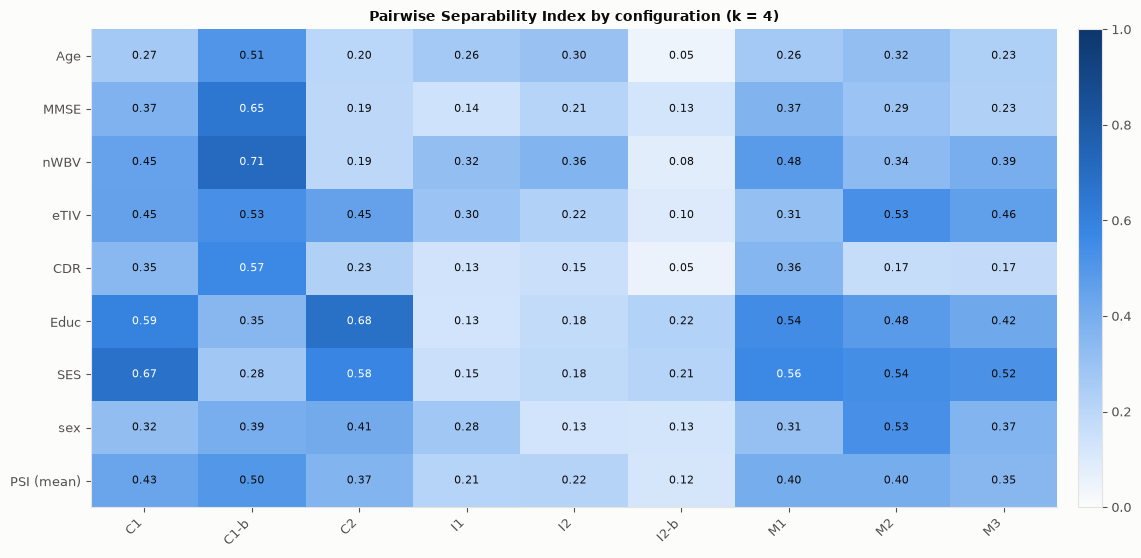

1252

In [5]:
fig = psi_heatmap(psi, f"Pairwise Separability Index by configuration (k = {K})")
fig.savefig(OUT / "psi_table_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

latex = labelled.copy()
for var in psi.index:
    best = psi.loc[var].idxmax()
    latex.loc[var, best] = r"\textbf{" + latex.loc[var, best] + "}"
(OUT / "psi_table.tex").write_text(latex.to_latex(escape=False), encoding="utf-8")

## 4. Selection

The configuration with the highest aggregate PSI is selected.

In [6]:
ranking = psi.loc["PSI (mean)"].sort_values(ascending=False)
display(ranking.round(3).to_frame("aggregate PSI"))
selected = ranking.index[0]
print(f"Selected configuration: {selected} (PSI = {ranking.iloc[0]:.3f})")

(OUT / "selection.json").write_text(json.dumps({
    "k": K, "selected": selected, "m3_metric": m3_metric,
    "aggregate_psi": ranking.round(4).to_dict(),
}, indent=2), encoding="utf-8")

labels = pd.DataFrame({n: results[n]["labels"] for n in ORDER})
labels.insert(0, "patient_id", df["patient_id"])
labels.to_csv(OUT / "labels.csv", index=False)

,aggregate PSI
C1-b,0.497
C1,0.434
M2,0.400
M1,0.399
C2,0.367
M3,0.350
I2,0.218
I1,0.213
I2-b,0.119


Selected configuration: C1-b (PSI = 0.497)


## 5. Summary of each configuration

Cluster medians, the share of patients with CDR > 0 and the share of men.

In [7]:
def cluster_summary(labels):
    g = df.assign(cluster=labels).groupby("cluster")
    t = g.agg(n=("Age", "size"), Age=("Age", "median"), MMSE=("MMSE", "median"), nWBV=("nWBV", "median"),
              eTIV=("eTIV", "median"), Educ=("Educ", "median"), SES=("SES", "median"))
    t["CDR>0 (%)"] = g["CDR"].apply(lambda s: 100 * (s > 0).mean()).round(0)
    t["men (%)"] = (100 * g["sex"].mean()).round(0)
    return t

summaries = []
for n in ORDER:
    t = cluster_summary(results[n]["labels"]).round(3)
    print(f"\n{n}  (PSI = {psi.loc['PSI (mean)', n]:.3f})")
    display(t)
    summaries.append(t.assign(config=n).reset_index())
pd.concat(summaries).to_csv(OUT / "cluster_summaries.csv", index=False)


C1  (PSI = 0.434)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,41,68.0,29.0,0.789,1372.0,4.0,3.0,20.0,12.0
2,64,73.5,29.0,0.734,1605.0,5.0,1.0,36.0,75.0
3,76,75.0,29.0,0.754,1391.0,2.0,2.0,32.0,14.0
4,35,78.0,23.0,0.705,1419.0,1.0,4.0,80.0,20.0



C1-b  (PSI = 0.497)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,62,58.0,30.0,0.810,1398.5,4.0,2.0,6.0,32.0
2,81,78.0,29.0,0.745,1390.0,3.0,2.0,31.0,7.0
3,38,78.0,28.0,0.720,1681.5,4.0,2.0,53.0,84.0
4,35,78.0,21.0,0.699,1461.0,2.0,4.0,97.0,37.0



C2  (PSI = 0.367)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,51,74.0,29.0,0.736,1637.0,5.0,2.0,35.0,86.0
2,58,69.5,29.0,0.770,1367.0,3.0,2.0,22.0,9.0
3,46,75.0,29.0,0.742,1390.5,4.0,1.0,28.0,13.0
4,61,77.0,27.0,0.743,1445.0,2.0,4.0,64.0,26.0


... (8 outputs left out)


M2  (PSI = 0.400)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,59,69.0,29.0,0.784,1392.0,2.0,3.0,27.0,5.0
2,50,73.5,29.0,0.727,1609.5,5.0,1.0,38.0,78.0
3,75,77.0,28.0,0.745,1372.0,3.0,2.0,40.0,3.0
4,32,80.0,26.5,0.724,1478.5,2.0,3.5,56.0,84.0



M3  (PSI = 0.350)


,n,Age,MMSE,nWBV,eTIV,Educ,SES,CDR>0 (%),men (%)
cluster,,,,,,,,,
1,60,70.0,29.0,0.781,1393.5,2.0,4.0,27.0,17.0
2,58,74.5,29.0,0.730,1622.0,5.0,1.0,36.0,83.0
3,60,76.5,29.0,0.749,1362.0,3.0,2.0,40.0,10.0
4,38,77.5,27.0,0.716,1425.5,3.0,3.0,58.0,18.0


## 6. Cluster profiles of every configuration

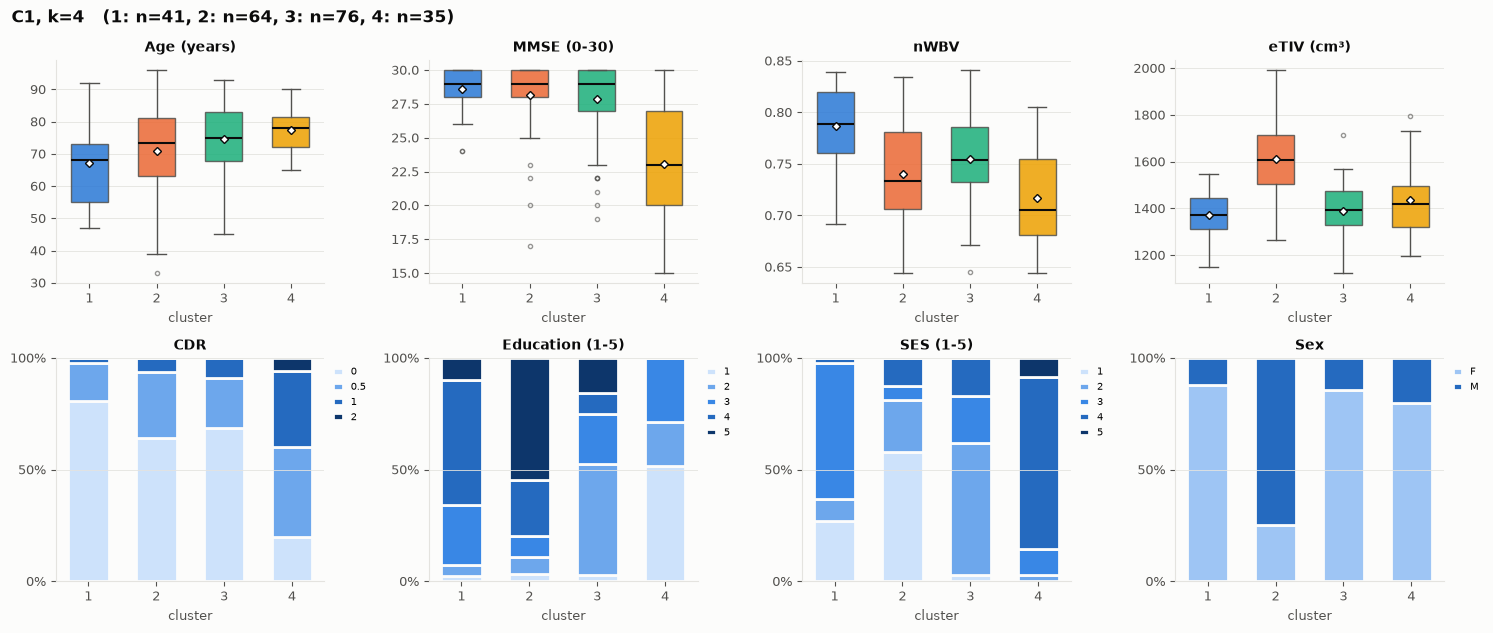

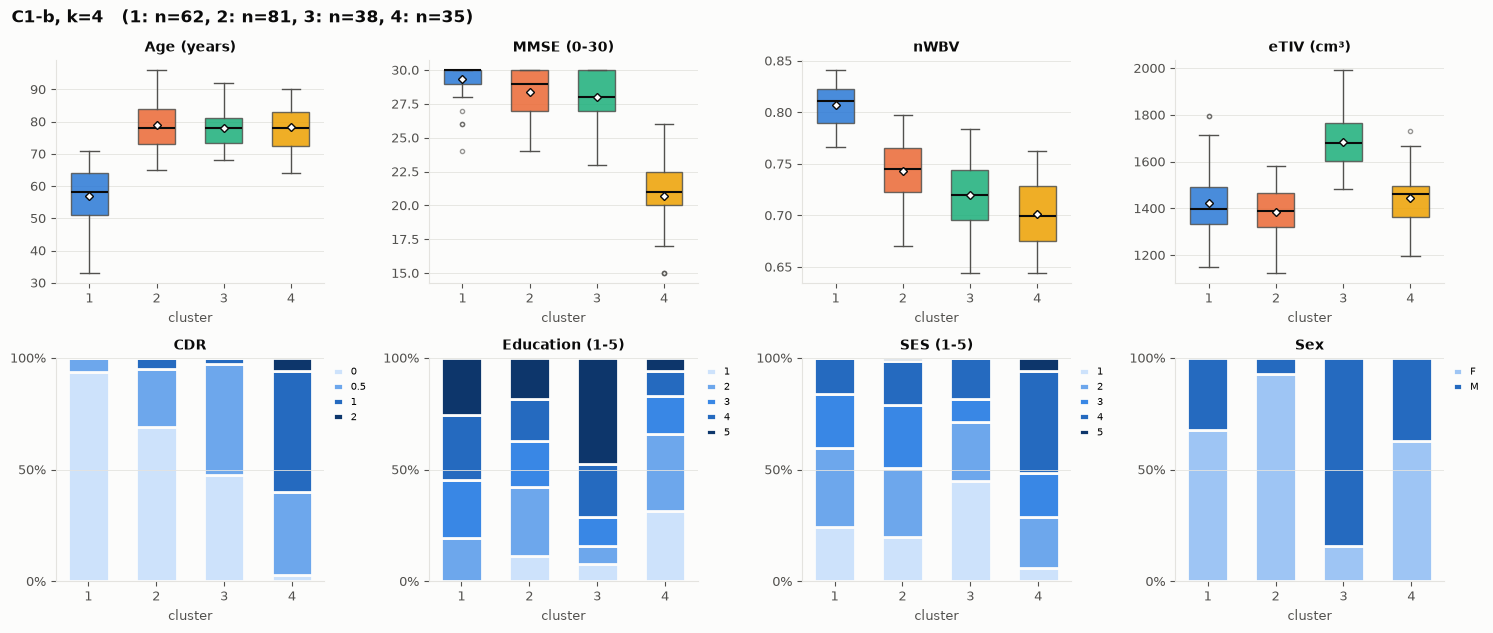

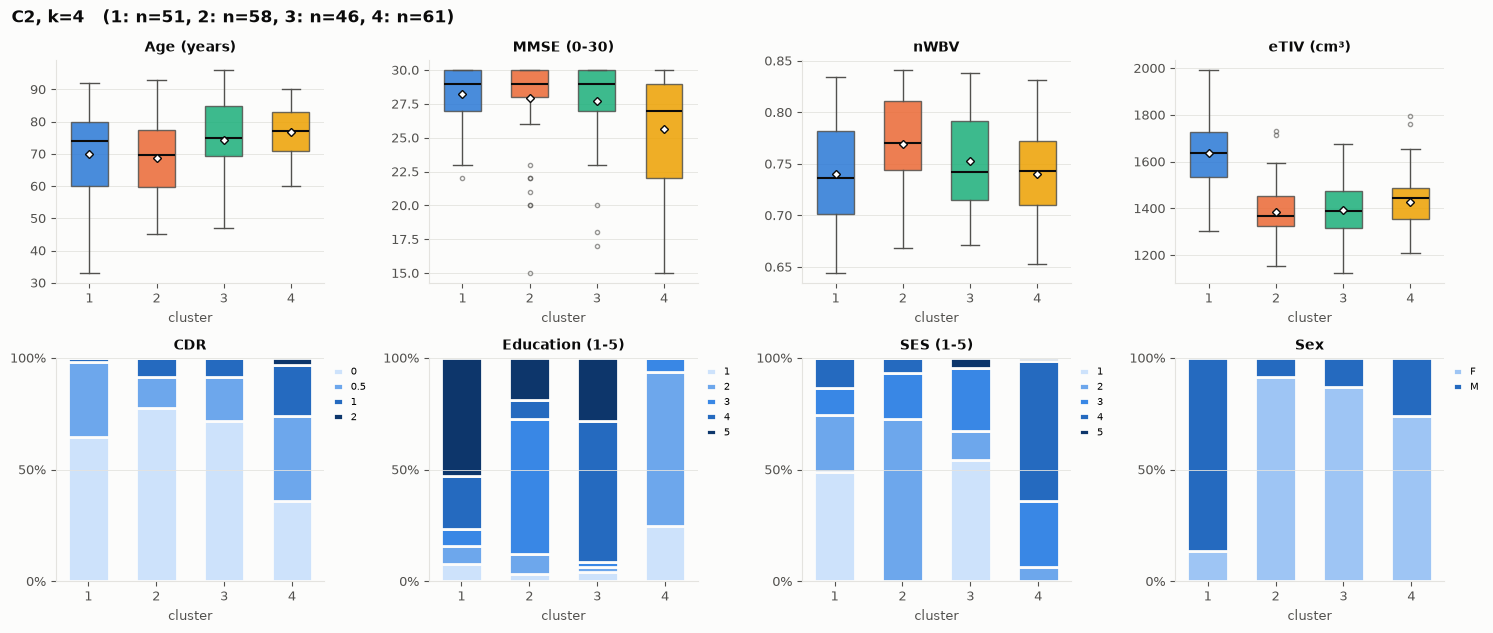

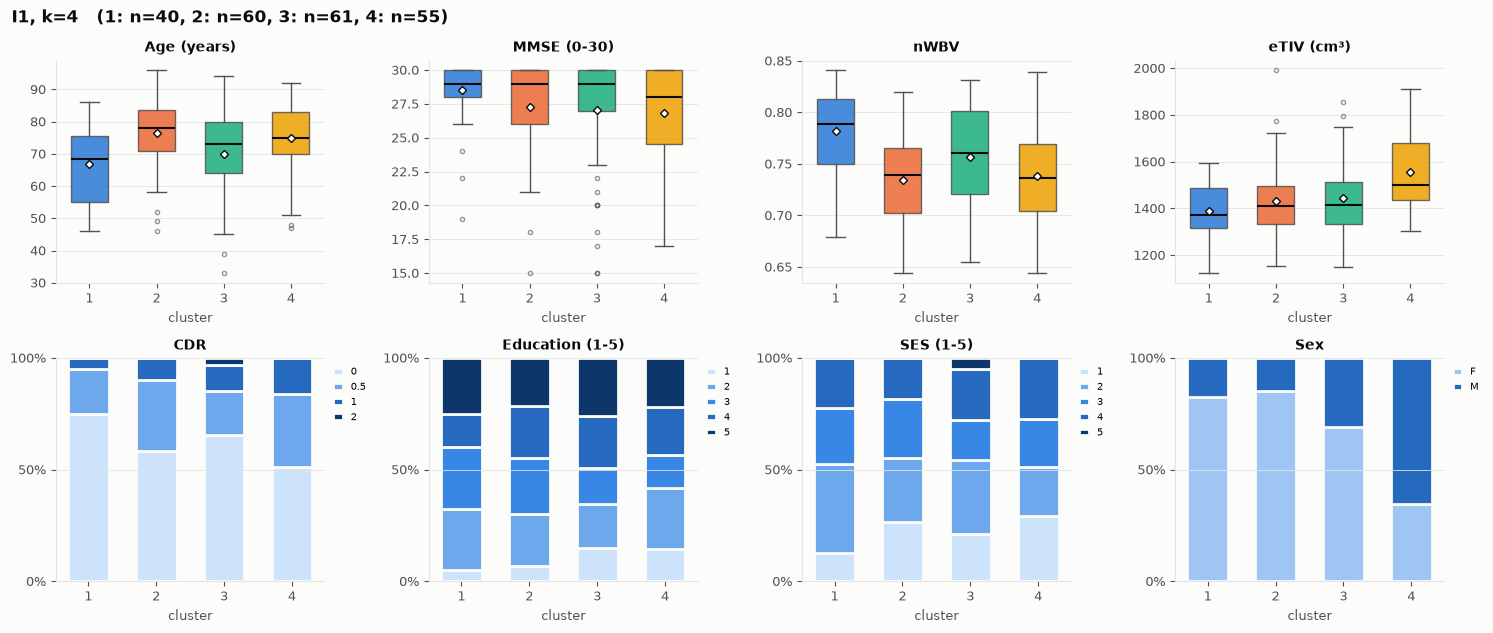

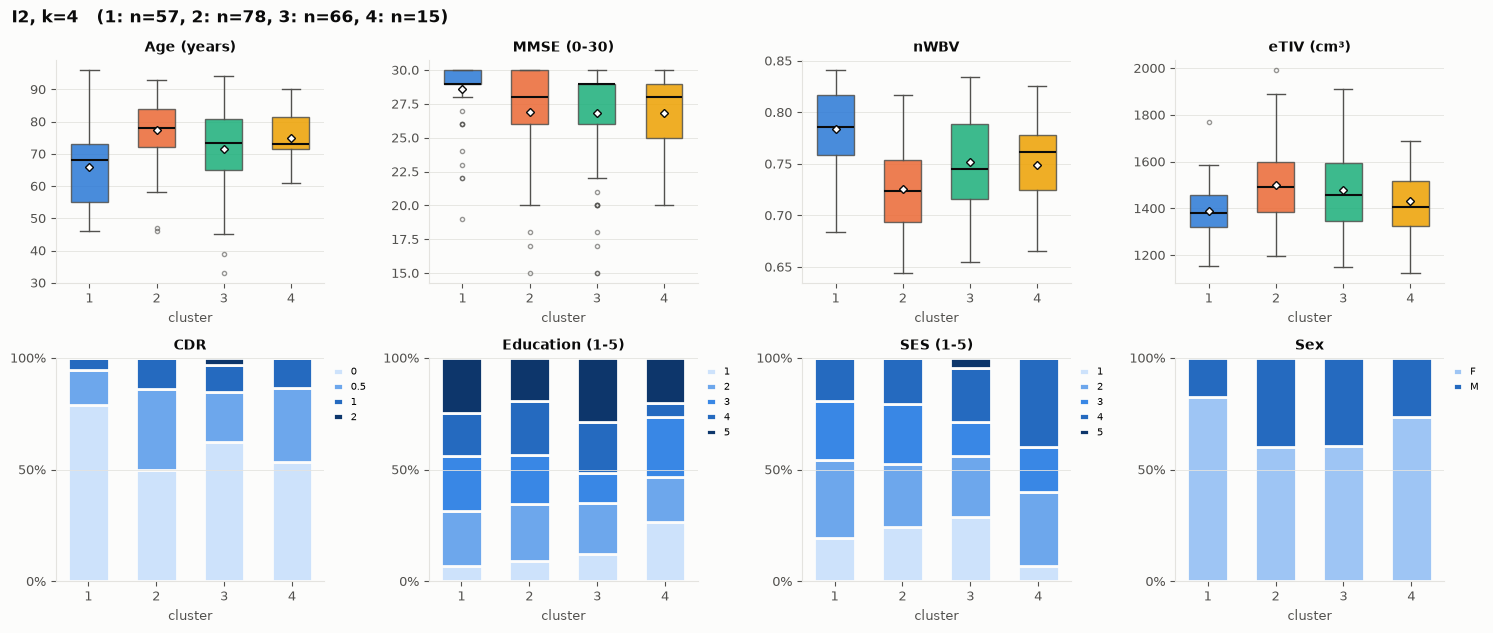

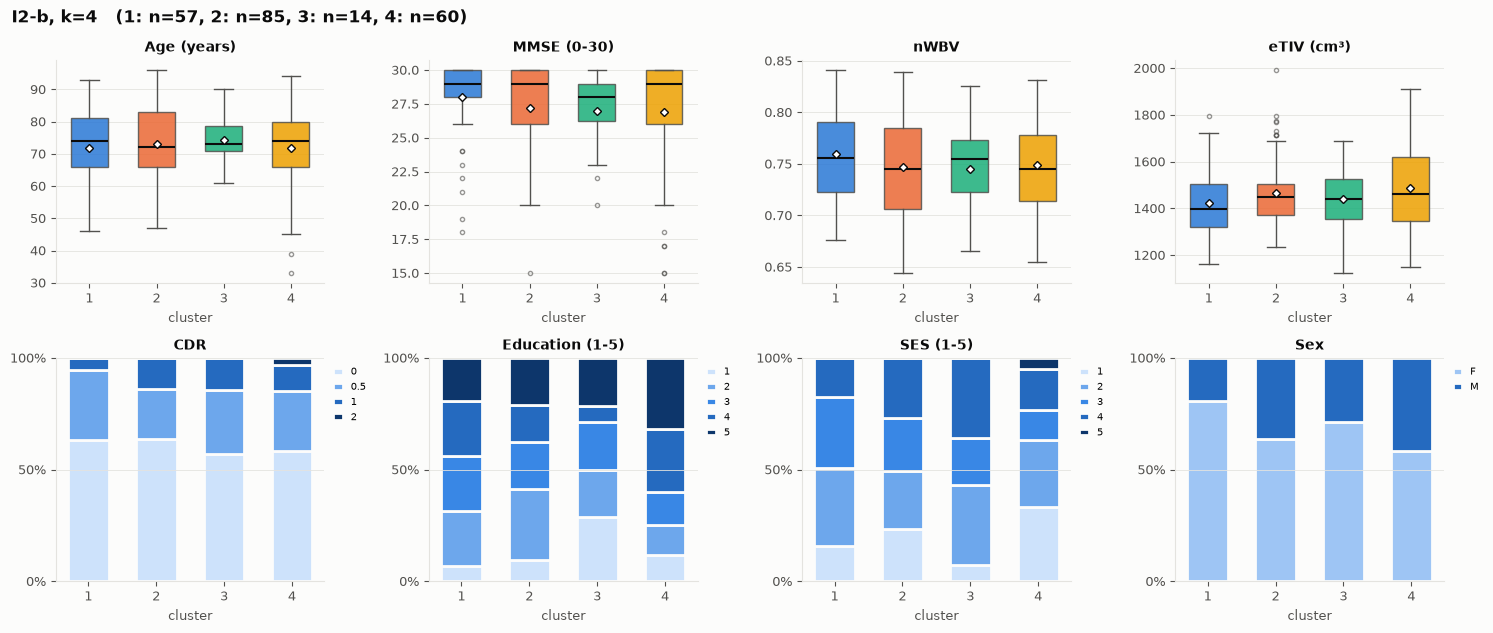

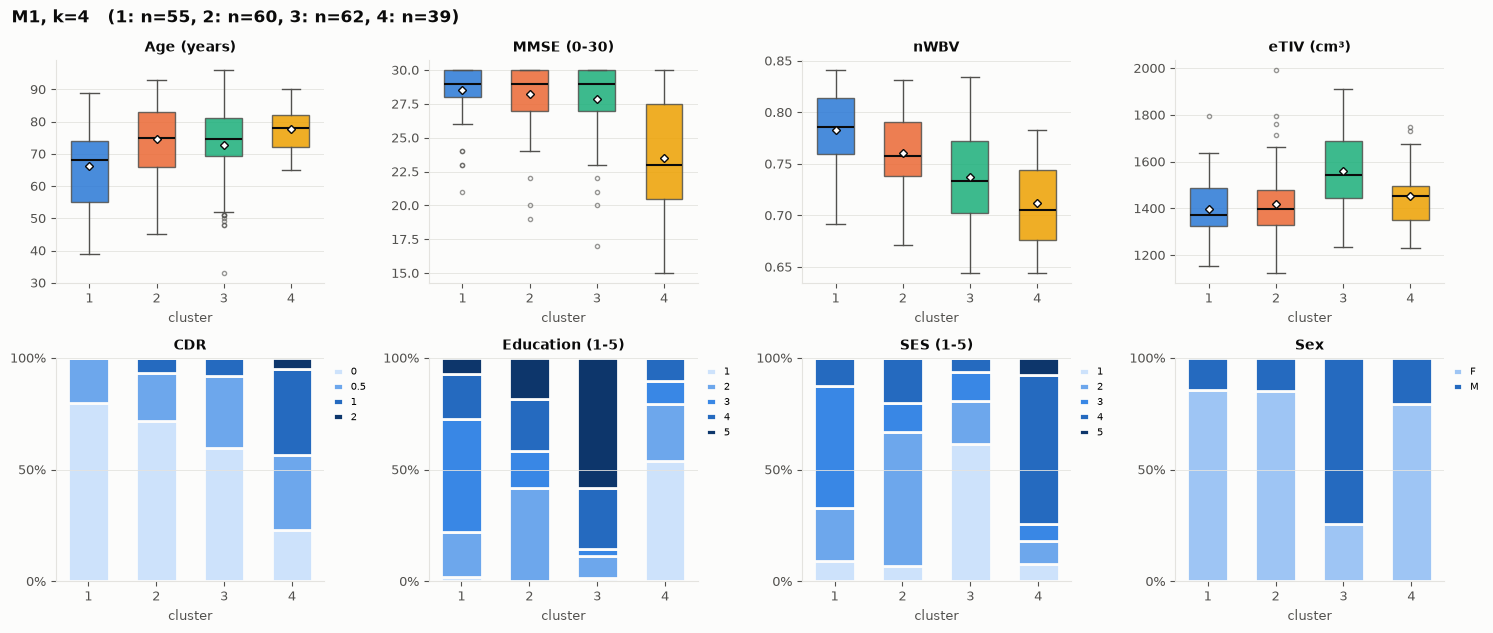

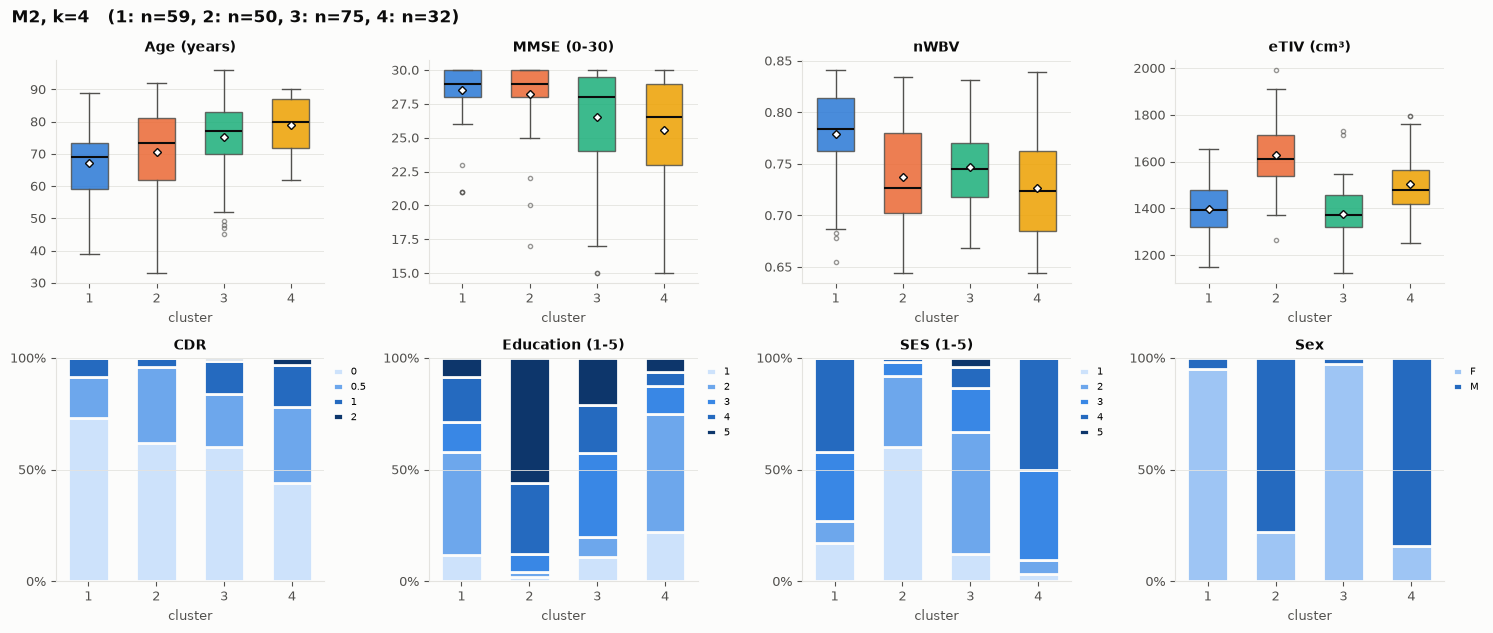

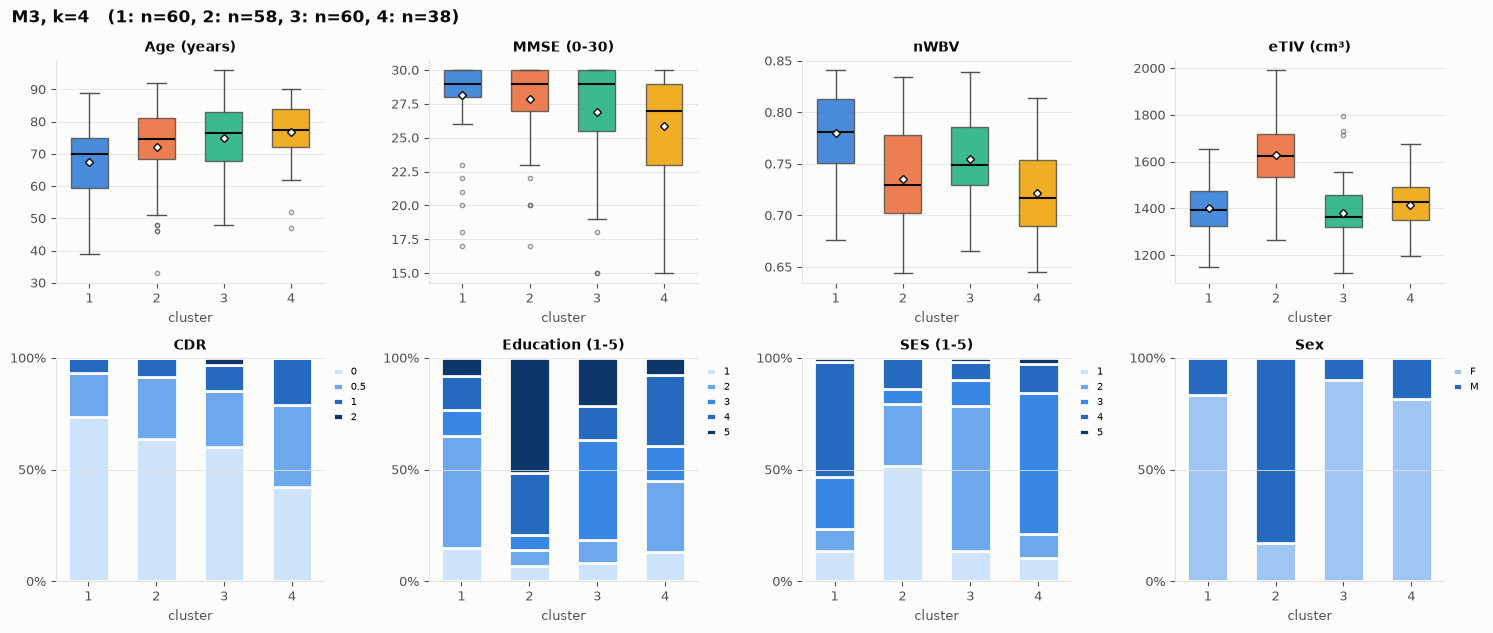

In [8]:
for n in ORDER:
    fig = cluster_profile(df, results[n]["labels"], f"{n}, k={K}")
    fig.savefig(OUT / f"profile_{n}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 7. Medoid patients

C1-b uses k-means, whose centroids are not real patients, so it has no medoids.

In [9]:
for n in ORDER:
    r = results[n]
    if r["medoids"] is None:
        continue
    print(f"\n{n}")
    display(medoid_table(df, r["labels"], r["medoids"]))


C1


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,41,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,64,OAS1_0256,M,70,30.0,0.0,0.739,1660,5.0,1.0
2,3,76,OAS1_0237,F,72,27.0,0.0,0.764,1322,2.0,2.0
3,4,35,OAS1_0425,F,78,23.0,1.0,0.715,1461,1.0,4.0



C2


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,51,OAS1_0256,M,70,30.0,0.0,0.739,1660,5.0,1.0
1,2,58,OAS1_0070,F,63,30.0,0.0,0.801,1327,3.0,2.0
2,3,46,OAS1_0195,F,76,28.0,0.0,0.766,1346,4.0,1.0
3,4,61,OAS1_0432,F,72,26.0,0.5,0.773,1453,2.0,4.0



I1


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,40,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,60,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
2,3,61,OAS1_0308,F,78,15.0,2.0,0.703,1401,3.0,3.0
3,4,55,OAS1_0016,M,82,27.0,0.5,0.739,1477,2.0,4.0


... (4 outputs left out)


M2


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,59,OAS1_0341,F,71,30.0,0.0,0.772,1479,2.0,4.0
1,2,50,OAS1_0256,M,70,30.0,0.0,0.739,1660,5.0,1.0
2,3,75,OAS1_0272,F,75,26.0,0.5,0.745,1355,3.0,2.0
3,4,32,OAS1_0016,M,82,27.0,0.5,0.739,1477,2.0,4.0



M3


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,60,OAS1_0341,F,71,30.0,0.0,0.772,1479,2.0,4.0
1,2,58,OAS1_0256,M,70,30.0,0.0,0.739,1660,5.0,1.0
2,3,60,OAS1_0272,F,75,26.0,0.5,0.745,1355,3.0,2.0
3,4,38,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
